In [1]:
from utils import trainingHR, resultsAnalysis, CPAnalysis, plot_CPs, get_distrib_HR, residual_threshold,AUROC_by_player_res, AUCPR_by_player_res
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import warnings
import numpy as np
from scipy.stats import uniform, loguniform, randint
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
#message="We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions." message fake data

##### Entrainement complet (tous les modèles + Pipeline + RandomizedSearchCV)

In [2]:
train = trainingHR('global_data_7_july_2023_16_may_2025.xlsx')
n_iter_search=200
train_size=0.7
train.predictions_HR('FC_moyenne',5,n_iter_search,train_size, True)

MHSC-45
number of observations = 913

 --- 492.98 secondes for this player pipeline --- 

 --- 3.818 secondes for this player pipeline --- 

 --- 503.383 secondes for this player pipeline --- 

 --- 3.345 secondes for this player pipeline --- 

 --- 2163.687 secondes for this player pipeline --- 
MHSC-20
number of observations = 786

 --- 406.379 secondes for this player pipeline --- 

 --- 2.903 secondes for this player pipeline --- 

 --- 430.252 secondes for this player pipeline --- 

 --- 2.508 secondes for this player pipeline --- 

 --- 1491.406 secondes for this player pipeline --- 
MHSC-14
number of observations = 988

 --- 513.526 secondes for this player pipeline --- 

 --- 3.903 secondes for this player pipeline --- 

 --- 517.351 secondes for this player pipeline --- 

 --- 3.731 secondes for this player pipeline --- 

 --- 778.556 secondes for this player pipeline --- 
MHSC-22
number of observations = 1081

 --- 544.278 secondes for this player pipeline --- 

 --- 4.854 se

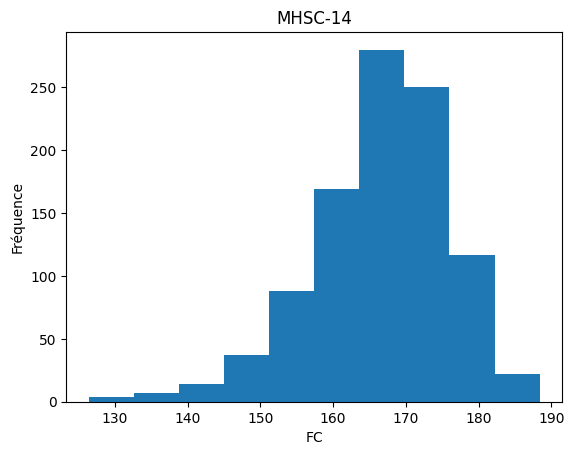

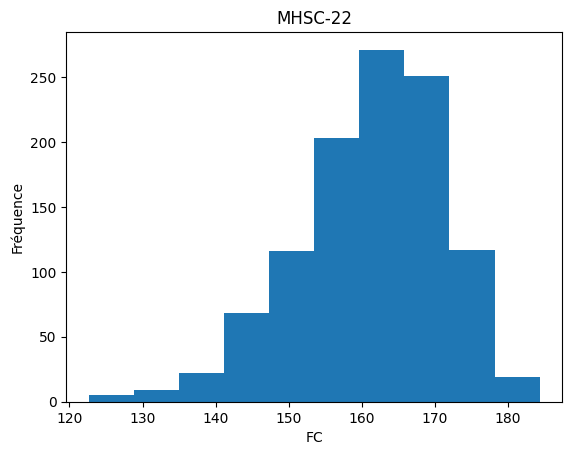

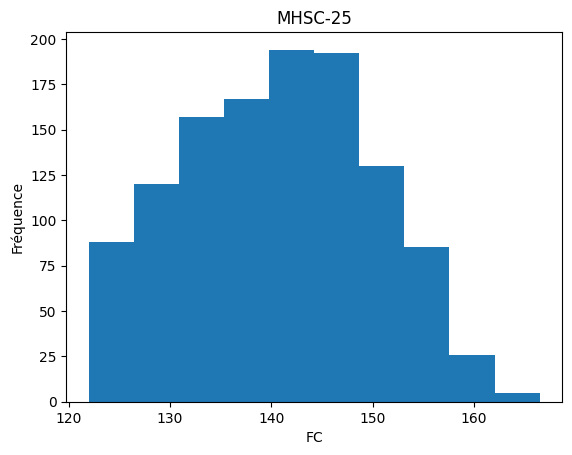

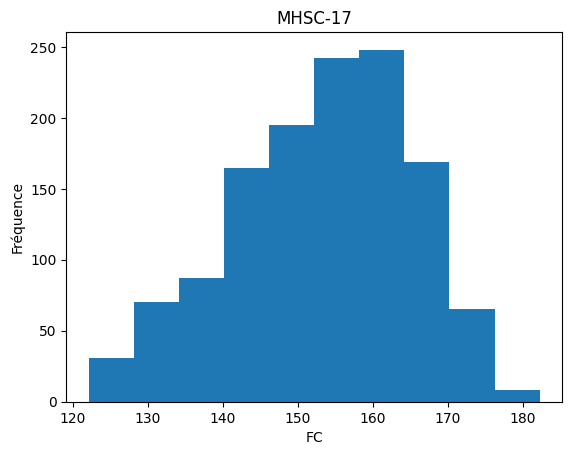

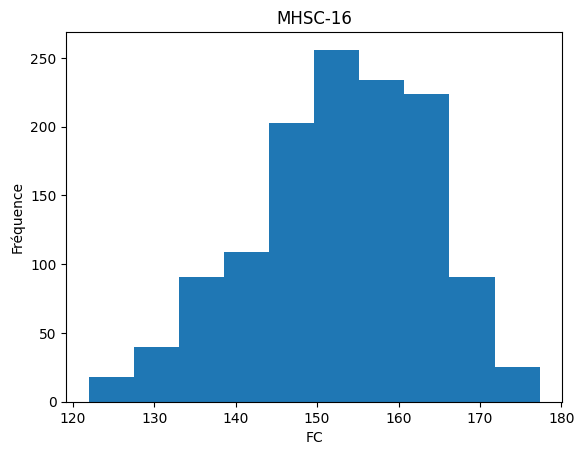

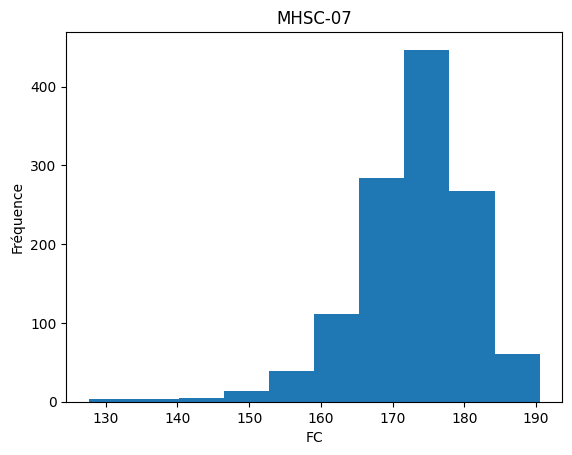

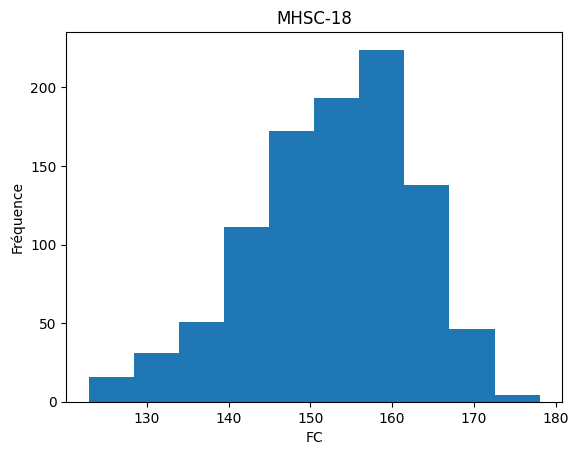

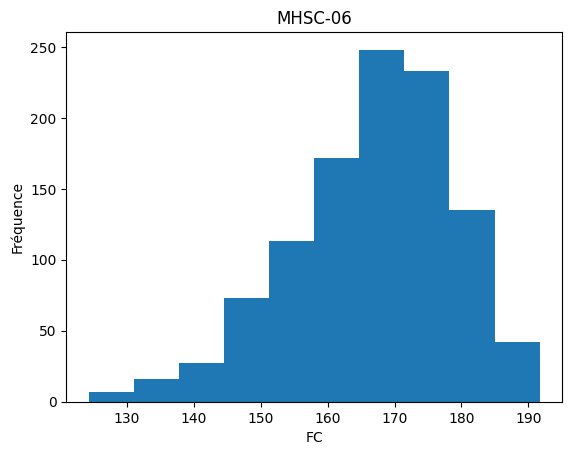

In [2]:
get_distrib_HR('global_data_7_july_2023_16_may_2025.xlsx',965,2000)

##### Analyse des résultats de 07072023_16052025_full.csv

RF a été le meilleur modèle pour 7 joueur(s)
SVR a été le meilleur modèle pour 14 joueur(s)
XGB a été le meilleur modèle pour 6 joueur(s)
KR a été le meilleur modèle pour 10 joueur(s)
LGBM a été le meilleur modèle pour 7 joueur(s)
               RMSE                 MAE                 R^2            \
               mean       std      mean       std      mean       std   
Regressor                                                               
KR         7.940197  2.481084  6.356998  2.219130  0.253168  0.502354   
LGBM       7.830491  1.527310  6.157533  1.198448  0.289516  0.268085   
RF         7.751916  1.574888  6.144973  1.278895  0.308386  0.234406   
SVR        7.979261  2.372035  6.376574  2.108273  0.253855  0.458282   
XGB        7.810699  1.503915  6.163732  1.163106  0.291031  0.250068   

               MAPE            
               mean       std  
Regressor                      
KR         0.040717  0.014185  
LGBM       0.039713  0.008671  
RF         0.039615  0.0

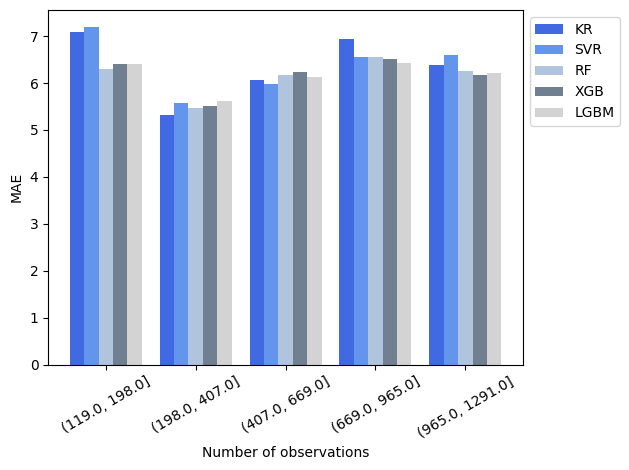

In [12]:
results=resultsAnalysis('results/07072023_16052025_full_prediction.csv')
#results.best_scaling()
dict_best_mod_player=results.count_best_model()
#results.best_features()
results.mean_std()
colors={"KR":"royalblue","SVR":'cornflowerblue',"RF":'lightsteelblue',"XGB":'slategrey',"LGBM":'lightgray'}

results.plot_bins('MAE',5,colors)
#results.get_best_player()


##### Conformal Prediction + Baseline

###### Computation

In [ ]:
path_data='global_data_7_july_2023_16_may_2025.xlsx'
conformal_prediction=trainingHR(path_data)
train_size=0.7
test_size=0.2
calibration_size=0.1  
target='FC_moyenne'
alpha=[0.1]
alphas=np.concatenate((alpha,np.linspace(0.1,0.5,30)))
path_result='results/07072023_16052025_full_prediction.csv'
best_players=['MHSC-71','MHSC-11','MHSC-10','MHSC-29','MHSC-67','MHSC-81','MHSC-45','MHSC-32','MHSC-51', 'MHSC-62',
              'MHSC-75','MHSC-18','MHSC-73','MHSC-56','MHSC-69','MHSC-19','MHSC-65','MHSC-08','MHSC-23','MHSC-66',
              'MHSC-07']
#pas de features selector ici car les modèles sont déjà entrainés pour écarter certaines features (xgb,kernel,rf,LGBM,..)
dict_params_search_qr_l={"XGB":{"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), 
                    "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)},
                    "LGBM":{"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), 
                    "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)}
                    }
dict_params_search_qr_u={"XGB":{"model__n_estimators": randint(200,1000), "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)},
                         "LGBM":{"model__n_estimators": randint(200,1000), "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)}
                         }  
dict_params_search={                        
                "RF": {"scaling":[MinMaxScaler(),StandardScaler()],'model__n_estimators': randint(200,1000),'model__max_depth' : randint(4,12)},
                "SVR": {"scaling":[MinMaxScaler(),StandardScaler()],'model__kernel':['rbf','linear','sigmoid'], "model__gamma": loguniform(1e-4,10), "model__C": loguniform(5e-2,5e4)},
                "XGB": {"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)},                
                "KR": {"scaling":[MinMaxScaler(),StandardScaler()],'model__kernel':['rbf','linear','sigmoid'], "model__alpha": loguniform(1e-5,10), "model__gamma": loguniform(1e-4,10)},
                "LGBM": {"scaling":[MinMaxScaler(),StandardScaler()],"model__n_estimators": randint(200,1000), "model__max_depth":randint(4,12), "model__learning_rate": loguniform(1e-3, 1e-1)}          
                }                 
cv_search=5
cv_CV_plus=20
n_iter_search=200
deviations_int=range(0,15)
deviations_percentage=np.linspace(0.01,0.2,10,endpoint=False)
types_deviation=['plus','minus']
types_anomalie=['from_test','full_synthetic']
thresholds_residual=range(1,15)

for deviation_percentage in deviations_percentage:
    for type_deviation in types_deviation:
        for type_anomalie in types_anomalie:
            conformal_prediction.split_conformal_prediction(players_tested=best_players,train_size=train_size,test_size=test_size,cal_size=calibration_size,target=target,dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,alphas=alphas,save_test_results=True,deviation=deviation_percentage,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result)
            conformal_prediction.conformalized_quantile_regression(players_tested=best_players, train_size=train_size,test_size=test_size,cal_size=calibration_size, target=target, dict_params_search_qr_l=dict_params_search_qr_l, dict_params_search_qr_u=dict_params_search_qr_u, cv_search=cv_search, n_iter_search=n_iter_search, alphas=alpha, save_test_results=True,deviation=deviation_percentage,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result)
            # conformal_prediction.cross_conformal_prediction(players_tested=best_players,train_size=0.8,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_test_results=True,deviation=deviation_percentage,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result,cv_CV_plus=cv_CV_plus)
            # conformal_prediction.cross_conformal_prediction(players_tested=best_players,train_size=0.8,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_test_results=True,deviation=deviation_percentage,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result,is_jackknife_plus=True) fonctionne pas sur player 07
            residual_threshold(path_data=path_data,train_size=0.8,path_result=path_result,target=target,cv_search=cv_search,n_iter_search=n_iter_search,thresholds=thresholds_residual,players_tested=best_players,deviation=deviation_percentage,type_deviation=type_deviation,type_anomalie=type_anomalie)


for deviation_int in deviations_int:
    for type_deviation in types_deviation:
        for type_anomalie in types_anomalie:
            conformal_prediction.split_conformal_prediction(players_tested=best_players,train_size=train_size,test_size=test_size,cal_size=calibration_size,target=target,dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,alphas=alphas,save_test_results=True,deviation=deviation_int,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result)
            conformal_prediction.conformalized_quantile_regression(players_tested=best_players, train_size=train_size,test_size=test_size,cal_size=calibration_size, target=target, dict_params_search_qr_l=dict_params_search_qr_l, dict_params_search_qr_u=dict_params_search_qr_u, cv_search=cv_search, n_iter_search=n_iter_search, alphas=alpha, save_test_results=True,deviation=deviation_int,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result)
            # conformal_prediction.cross_conformal_prediction(players_tested=best_players,train_size=0.8,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_test_results=True,deviation=deviation_int,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result,cv_CV_plus=cv_CV_plus)
            # conformal_prediction.cross_conformal_prediction(players_tested=best_players,train_size=0.8,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_test_results=True,deviation=deviation_int,type_deviation=type_deviation,type_anomalie=type_anomalie,best_regressor=True,path_result=path_result,is_jackknife_plus=True) #fonctionne pas sur player 07
            residual_threshold(path_data=path_data,train_size=0.8,path_result=path_result,target=target,cv_search=cv_search,n_iter_search=n_iter_search,thresholds=thresholds_residual,players_tested=best_players,deviation=deviation_int,type_deviation=type_deviation,type_anomalie=type_anomalie)

#for jackknife+ and CV+ (computationally more expensive)
conformal_prediction.cross_conformal_prediction_bis(players_tested=best_players,train_size=0.8,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_test_results=True,deviations=deviations_int,type_deviations=types_deviation,type_anomalies=types_anomalie,best_regressor=True,path_result=path_result,is_jackknife_plus=True) 
conformal_prediction.cross_conformal_prediction_bis(players_tested=best_players,train_size=0.8,target=target, alphas=alphas, dict_params_search=dict_params_search,cv_search=cv_search,n_iter_search=n_iter_search,save_test_results=True,deviations=deviations_int,type_deviations=types_deviation,type_anomalies=types_anomalie,best_regressor=True,path_result=path_result,cv_CV_plus=cv_CV_plus) 


MHSC-71
MHSC-11
MHSC-10
MHSC-29
MHSC-67
MHSC-81
MHSC-45
MHSC-32
MHSC-51
MHSC-62
MHSC-75
MHSC-18
MHSC-73
MHSC-56
MHSC-69
MHSC-19
MHSC-65
MHSC-08
MHSC-23
MHSC-66
MHSC-07


###### Plot results

In [ ]:
best_players=['MHSC-71','MHSC-11','MHSC-10','MHSC-29','MHSC-67','MHSC-81','MHSC-45','MHSC-32','MHSC-07','MHSC-51',
              'MHSC-75','MHSC-18','MHSC-73','MHSC-56','MHSC-69','MHSC-19','MHSC-65','MHSC-08','MHSC-23','MHSC-66',
              'MHSC-62']
def AD_metrics(path,players_tested):
    TNR = [] 
    TPR = []
    PPV=[]
    NPV=[]
    for player in players_tested:
        result = CPAnalysis(path)
        tnr, tpr,ppv,npv = result.coverage_and_anomalies_by_player(player)
        TNR.append(tnr)
        TPR.append(tpr)
        PPV.append(ppv)
        NPV.append(npv)
    TNR_array=np.array(TNR)
    TPR_array=np.array(TPR)
    PPV_array=np.array(PPV)
    NPV_array=np.array(NPV)
    return((TNR_array.mean(),TNR_array.std()),(TPR_array.mean(),TPR_array.std()),(PPV_array.mean(),PPV_array.std()),(NPV_array.mean(),NPV_array.std()))

def interval_size_full(path,players_tested):
    mean_player=[]
    for player in players_tested:
        result = CPAnalysis(path)
        stats=result.interval_size_analysis_full_by_player(player)
        mean_player.append(int(stats['mean']))
    mean_array=np.array(mean_player)
    return(mean_array.mean(),mean_array.std())
        
print("from_test")
print('TNR, TPR, PPV and NPV')  
print(AD_metrics('results/SCP/0.5prevalence/+10bpm/from_test/07072023_16052025_alpha0.1.csv',best_players))
print(AD_metrics('results/CQR/0.5prevalence/+10bpm/from_test/07072023_16052025_alpha0.1.csv',best_players))
print(AD_metrics('results/CV+/0.5prevalence/+10bpm/from_test/07072023_16052025_cvccp20_alpha0.1.csv',best_players))
print(AD_metrics('results/Jackknife+/0.5prevalence/+10bpm/from_test/07072023_16052025_alpha0.1.csv',best_players))
print('Interval size full')
print(interval_size_full('results/SCP/0.5prevalence/+10bpm/from_test/07072023_16052025_alpha0.1.csv',best_players))
print(interval_size_full('results/CQR/0.5prevalence/+10bpm/from_test/07072023_16052025_alpha0.1.csv',best_players))
print(interval_size_full('results/CV+/0.5prevalence/+10bpm/from_test/07072023_16052025_cvccp20_alpha0.1.csv',best_players))
print(interval_size_full('results/Jackknife+/0.5prevalence/+10bpm/from_test/07072023_16052025_alpha0.1.csv',best_players))

from_test
TNR, TPR, PPV and NPV
((np.float64(0.9190614203476425), np.float64(0.054355079864109514)), (np.float64(0.46825481608058844), np.float64(0.20369059029194767)), (np.float64(0.8646544124050014), np.float64(0.06980483268013807)), (np.float64(0.6486019348968326), np.float64(0.09390613678680869)))
((np.float64(0.9231173319489013), np.float64(0.0596706791829931)), (np.float64(0.3430485618154358), np.float64(0.180505369235021)), (np.float64(0.8133194609386776), np.float64(0.14505326622541184)), (np.float64(0.5920375928530415), np.float64(0.06094051619452738)))
((np.float64(0.8386836745727119), np.float64(0.09188671911152604)), (np.float64(0.5789891306032094), np.float64(0.15713397951271188)), (np.float64(0.7838004914680686), np.float64(0.10663350128827029)), (np.float64(0.6740510223249233), np.float64(0.0797498812427893)))
((np.float64(0.833311041647883), np.float64(0.09476271408995764)), (np.float64(0.5857556389102915), np.float64(0.16067570833721592)), (np.float64(0.782523533802013

###### Plot anomaly detection performances against various metrics 

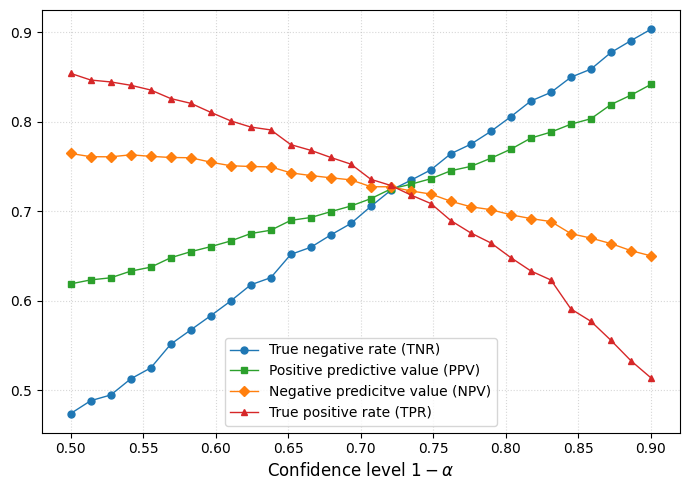

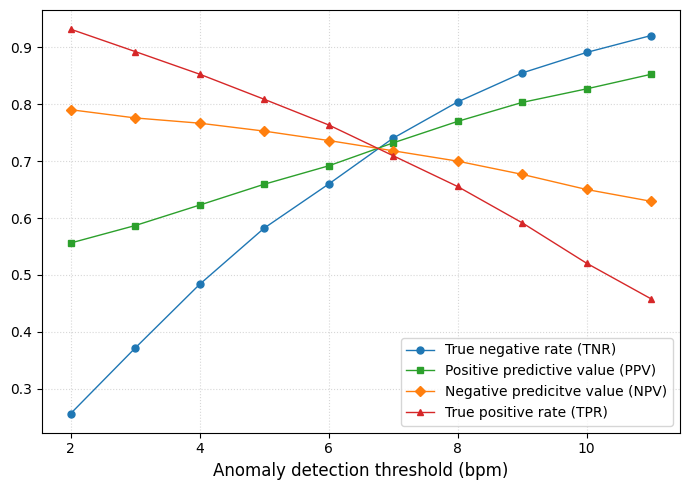

In [12]:
def plot_metrics_anomaly_CP_alpha(method,type_anomaly,deviation):
    coverages = [] #or TNR
    TPR = []
    PPV=[]
    NPV=[]
    alphas=np.linspace(0.1,0.5,30)
    for alpha in alphas:
        result = CPAnalysis(f'results/{method}/0.5prevalence/+{deviation}bpm/{type_anomaly}/07072023_16052025_alpha{alpha}.csv')
        coverage, anomalies_detected,ppv,npv = result.coverage_and_anomalies()
        coverages.append(coverage)
        TPR.append(anomalies_detected)
        PPV.append(ppv)
        NPV.append(npv)
    # alpha_min, alpha_max = alpha_scp.min(), alpha_scp.max()
    # alpha_theory = np.linspace(alpha_min-0.01, alpha_max+0.01, 200)
    plt.figure(figsize=(7, 5))
    plt.plot(1-alphas, coverages,color="tab:blue",marker="o",linestyle="-",linewidth=1,markersize=5,label="True negative rate (TNR)")
    #plt.plot(alpha_theory, 1-alpha_theory,color="black",linestyle="--",linewidth=1,label=r"Theoretical coverage $(1-\alpha$)")
    plt.plot(1-alphas, PPV,color="tab:green",marker="s",linestyle="-",linewidth=1,markersize=5,label="Positive predictive value (PPV)")
    plt.plot(1-alphas, NPV,color="tab:orange",marker="D",linestyle="-",linewidth=1,markersize=5,label="Negative predicitve value (NPV)")
    plt.plot(1-alphas, TPR,color="tab:red",marker="^",linestyle="-",linewidth=1,markersize=5,label="True positive rate (TPR)")
    plt.xlabel(r"Confidence level $1-\alpha$", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

def plot_metrics_anomaly_CP_deviation(method,type_anomaly,alpha):
    coverages = []
    TPR = []
    PPV=[]
    NPV=[]
    deviations=range(5,15)
    #deviations=np.linspace(0.01,0.2,10,endpoint=False)
    for deviation in deviations:
        result = CPAnalysis(f'results/{method}/0.5prevalence/+{deviation}bpm/{type_anomaly}/07072023_16052025_alpha{alpha}.csv')
        coverage, anomalies_detected,ppv,npv = result.coverage_and_anomalies()
        coverages.append(coverage)
        TPR.append(anomalies_detected)
        PPV.append(ppv)
        NPV.append(npv)
    plt.figure(figsize=(7, 5))
    plt.plot(deviations, coverages,color="tab:blue",marker="o",linestyle="-",linewidth=1,markersize=5,label="True negative rate (TNR)")
    plt.plot(deviations, PPV,color="tab:green",marker="s",linestyle="-",linewidth=1,markersize=5,label="Positive predictive value (PPV)")
    plt.plot(deviations, NPV,color="tab:orange",marker="D",linestyle="-",linewidth=1,markersize=5,label="Negative predicitve value (NPV)")
    plt.plot(deviations, TPR,color="tab:red",marker="^",linestyle="-",linewidth=1,markersize=5,label="True positive rate (TPR)")
    plt.xlabel(r"Deviation (bpm)", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

def plot_metrics_anomaly_residual_threshold(type_anomaly,deviation):
    coverages = []
    TPR = []
    PPV=[]
    NPV=[]
    thresholds_residual=range(2,12)
    for threshold in thresholds_residual:
        result = CPAnalysis(f'results/Res-Threshold/0.5prevalence/+{deviation}bpm/{type_anomaly}/07072023_16052025_threshold{threshold}.csv')
        coverage, anomalies_detected,ppv,npv = result.coverage_and_anomalies()
        coverages.append(coverage)
        TPR.append(anomalies_detected)
        PPV.append(ppv)
        NPV.append(npv)
    # alpha_min, alpha_max = alpha_scp.min(), alpha_scp.max()
    # alpha_theory = np.linspace(alpha_min-0.01, alpha_max+0.01, 200)
    plt.figure(figsize=(7, 5))
    plt.plot(thresholds_residual, coverages,color="tab:blue",marker="o",linestyle="-",linewidth=1,markersize=5,label="True negative rate (TNR)")
    #plt.plot(alpha_theory, 1-alpha_theory,color="black",linestyle="--",linewidth=1,label=r"Theoretical coverage $(1-\alpha$)")
    plt.plot(thresholds_residual, PPV,color="tab:green",marker="s",linestyle="-",linewidth=1,markersize=5,label="Positive predictive value (PPV)")
    plt.plot(thresholds_residual, NPV,color="tab:orange",marker="D",linestyle="-",linewidth=1,markersize=5,label="Negative predicitve value (NPV)")
    plt.plot(thresholds_residual, TPR,color="tab:red",marker="^",linestyle="-",linewidth=1,markersize=5,label="True positive rate (TPR)")
    plt.xlabel(r"Anomaly detection threshold (bpm)", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

def plot_metrics_anomaly_residual_deviation(type_anomaly,threshold):
    coverages = []
    TPR = []
    PPV=[]
    NPV=[]
    deviations=range(5,15)
    #deviations=np.linspace(0.01,0.2,10,endpoint=False)
    for deviation in deviations:
        result = CPAnalysis(f'results/Res-Threshold/0.5prevalence/+{deviation}bpm/{type_anomaly}/07072023_16052025_threshold{threshold}.csv')
        coverage, anomalies_detected,ppv,npv = result.coverage_and_anomalies()
        coverages.append(coverage)
        TPR.append(anomalies_detected)
        PPV.append(ppv)
        NPV.append(npv)
    plt.figure(figsize=(7, 5))
    plt.plot(deviations, coverages,color="tab:blue",marker="o",linestyle="-",linewidth=1,markersize=5,label="True negative rate (TNR)")
    plt.plot(deviations, PPV,color="tab:green",marker="s",linestyle="-",linewidth=1,markersize=5,label="Positive predictive value (PPV)")
    plt.plot(deviations, NPV,color="tab:orange",marker="D",linestyle="-",linewidth=1,markersize=5,label="Negative predicitve value (NPV)")
    plt.plot(deviations, TPR,color="tab:red",marker="^",linestyle="-",linewidth=1,markersize=5,label="True positive rate (TPR)")
    plt.xlabel(r"Deviation (bpm)", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()

#TODO tester avec les -
method="SCP"
type_anomaly="from_test"
type_anomaly_bis="full_synthetic"
deviation=10
alpha=0.20789473684210524


plot_metrics_anomaly_CP_alpha(method,type_anomaly,deviation)
plot_metrics_anomaly_residual_threshold(type_anomaly,deviation)
# plot_metrics_anomaly_CP_deviation(method,type_anomaly,alpha)
# plot_metrics_anomaly_CP_deviation(method,type_anomaly_bis,alpha)

# plot_metrics_anomaly_CP_alpha(method,type_anomaly_bis,deviation)
#plot_metrics_anomaly_residual_threshold(type_anomaly_bis,deviation)
#plot_metrics_anomaly_residual_deviation(type_anomaly,threshold=8)

#plot_metrics_anomaly_residual_deviation(type_anomaly_bis,threshold=8)

###### ROC curve 

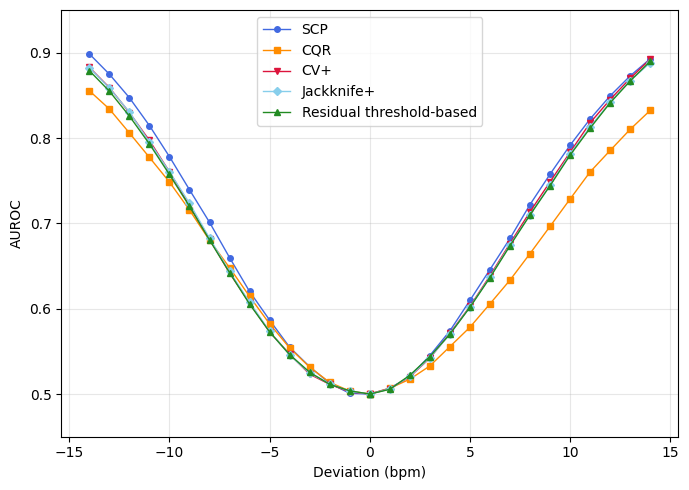

In [ ]:
best_players=['MHSC-71','MHSC-11','MHSC-10','MHSC-29','MHSC-67','MHSC-81','MHSC-45','MHSC-32','MHSC-07','MHSC-51',
              'MHSC-75','MHSC-18','MHSC-73','MHSC-56','MHSC-69','MHSC-19','MHSC-65','MHSC-08','MHSC-23','MHSC-66',
              'MHSC-62']

types_deviation=['plus','minus']
deviations_int=range(0,15)

def roc_CP(method,type_anomaly,deviation,type_deviation,players_tested):
    #on s'en fiche du alpha ou du threshold, les scores stockés sont les mêmes partout
    if type_deviation=='plus':
        str_type_deviation='+'
    elif type_deviation=='minus':
        str_type_deviation='-'
    else:
        raise(ValueError('type_deviation must be "plus" or "minus"'))
    if method=="CV+":
        result = CPAnalysis(f'results/{method}/0.5prevalence/{str_type_deviation}{deviation}bpm/{type_anomaly}/07072023_16052025_cvccp20_alpha0.1.csv')
    else:
        result = CPAnalysis(f'results/{method}/0.5prevalence/{str_type_deviation}{deviation}bpm/{type_anomaly}/07072023_16052025_alpha0.1.csv')
    auroc_list=[]
    for player in players_tested:
        auroc=result.AUROC_by_player(player)
        auroc_list.append(auroc)
    return np.array(auroc_list)

def roc_res(type_anomaly,deviation,type_deviation,players_tested):
    #on s'en fiche du alpha ou du threshold, les scores stockés sont les mêmes partout
    if type_deviation=='plus':
        str_type_deviation='+'
    elif type_deviation=='minus':
        str_type_deviation='-'
    else:
        raise(ValueError('type_deviation must be "plus" or "minus"'))
    path=f'results/Res-Threshold/0.5prevalence/{str_type_deviation}{deviation}bpm/{type_anomaly}/07072023_16052025_threshold1.csv'
    auroc_list=[]
    for player in players_tested:
        auroc=AUROC_by_player_res(path,player)
        auroc_list.append(auroc)
    return np.array(auroc_list)

def plot_auroc_deviation(type_anomaly):
    types_deviation = ["minus", "plus"]
    results = {"SCP": [],"CQR": [], "CV+": [],"Jackknife+": [],"Residual threshold-based": []}
    deviations = []
    for type_deviation in types_deviation:
        for deviation in deviations_int:
            signed_deviation = -deviation if type_deviation == "minus" else deviation
            deviations.append(signed_deviation)
            auroc_SCP = roc_CP('SCP',type_anomaly,deviation,type_deviation,best_players)
            auroc_CQR = roc_CP('CQR', type_anomaly, deviation,type_deviation, best_players)
            auroc_CVplus = roc_CP('CV+', type_anomaly, deviation,type_deviation, best_players)
            auroc_jackknifplus = roc_CP('Jackknife+', type_anomaly, deviation,type_deviation, best_players)
            auroc_res = roc_res(type_anomaly, deviation,type_deviation, best_players)
            results["SCP"].append((auroc_SCP.mean(), auroc_SCP.std()))
            results["CQR"].append((auroc_CQR.mean(), auroc_CQR.std()))
            results["Jackknife+"].append((auroc_jackknifplus.mean(), auroc_jackknifplus.std()))
            results["CV+"].append((auroc_CVplus.mean(), auroc_CVplus.std()))
            results["Residual threshold-based"].append((auroc_res.mean(), auroc_res.std()))
    order = np.argsort(deviations)
    deviations=np.array(deviations)[order]
    colors = {"SCP": "royalblue","CQR": "darkorange","Residual threshold-based": "forestgreen", "CV+":"crimson" ,"Jackknife+":"skyblue"}
    markers = {"SCP": "o","CQR": "s","Residual threshold-based": "^","CV+": "v","Jackknife+":"D"}
    plt.figure(figsize=(7, 5))
    for method in results:
        means = np.array([x[0] for x in results[method]])[order]
        stds = np.array([x[1] for x in results[method]])[order]
        plt.plot(
            deviations, means,
            marker=markers[method],
            color=colors[method],
            linewidth=1,
            label=method,
            markersize=4
        )
    plt.xlabel("Deviation (bpm)")
    plt.ylabel("AUROC")
    #plt.title(f'{type_anomaly}')
    plt.ylim(0.45, 0.95)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_auroc_deviation('from_test')
#plot_auroc_deviation('full_synthetic')

###### PR curve

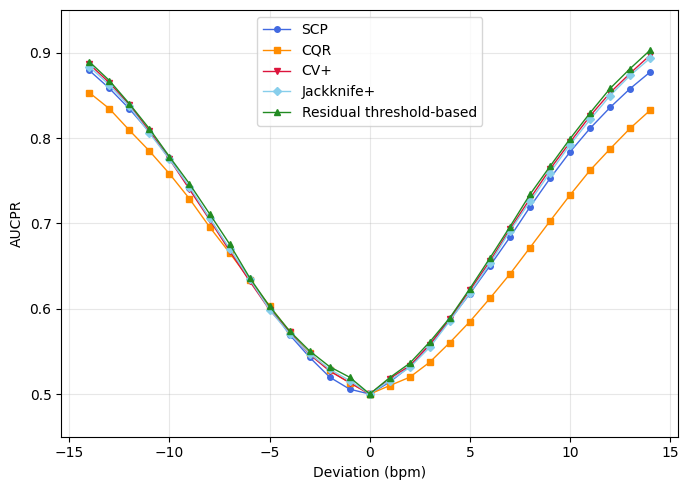

In [2]:
best_players=['MHSC-71','MHSC-11','MHSC-10','MHSC-29','MHSC-67','MHSC-81','MHSC-45','MHSC-32','MHSC-07','MHSC-51',
              'MHSC-75','MHSC-18','MHSC-73','MHSC-56','MHSC-69','MHSC-19','MHSC-65','MHSC-08','MHSC-23','MHSC-66',
              'MHSC-62']

types_deviation=['plus','minus']
deviations_int=range(0,15)

def pr_CP(method,type_anomaly,deviation,type_deviation,players_tested):
    #on s'en fiche du alpha ou du threshold, les scores stockés sont les mêmes partout
    if type_deviation=='plus':
        str_type_deviation='+'
    elif type_deviation=='minus':
        str_type_deviation='-'
    else:
        raise(ValueError('type_deviation must be "plus" or "minus"'))
    if method=="CV+":
        result = CPAnalysis(f'results/{method}/0.5prevalence/{str_type_deviation}{deviation}bpm/{type_anomaly}/07072023_16052025_cvccp20_alpha0.1.csv')
    else:
        result = CPAnalysis(f'results/{method}/0.5prevalence/{str_type_deviation}{deviation}bpm/{type_anomaly}/07072023_16052025_alpha0.1.csv')
    aucpr_list=[]
    for player in players_tested:
        aucpr=result.AUCPR_by_player(player)
        aucpr_list.append(aucpr)
    return np.array(aucpr_list)

def pr_res(type_anomaly,deviation,type_deviation,players_tested):
    #on s'en fiche du alpha ou du threshold, les scores stockés sont les mêmes partout
    if type_deviation=='plus':
        str_type_deviation='+'
    elif type_deviation=='minus':
        str_type_deviation='-'
    else:
        raise(ValueError('type_deviation must be "plus" or "minus"'))
    path=f'results/Res-Threshold/0.5prevalence/{str_type_deviation}{deviation}bpm/{type_anomaly}/07072023_16052025_threshold1.csv'
    aucpr_list=[]
    for player in players_tested:
        aucpr=AUCPR_by_player_res(path,player)
        aucpr_list.append(aucpr)
    return np.array(aucpr_list)

def plot_aucpr_deviation(type_anomaly):
    types_deviation = ["minus", "plus"]
    results = {"SCP": [],"CQR": [], "CV+": [],"Jackknife+": [],"Residual threshold-based": []}
    deviations = []
    for type_deviation in types_deviation:
        for deviation in deviations_int:
            signed_deviation = -deviation if type_deviation == "minus" else deviation
            deviations.append(signed_deviation)
            aucpr_SCP = pr_CP('SCP',type_anomaly,deviation,type_deviation,best_players)
            aucpr_CQR = pr_CP('CQR', type_anomaly, deviation,type_deviation, best_players)
            aucpr_CVplus = pr_CP('CV+', type_anomaly, deviation,type_deviation, best_players)
            aucpr_jackknifplus = pr_CP('Jackknife+', type_anomaly, deviation,type_deviation, best_players)
            aucpr_res = pr_res(type_anomaly, deviation,type_deviation, best_players)
            results["SCP"].append((aucpr_SCP.mean(), aucpr_SCP.std()))
            results["CQR"].append((aucpr_CQR.mean(), aucpr_CQR.std()))
            results["Jackknife+"].append((aucpr_jackknifplus.mean(), aucpr_jackknifplus.std()))
            results["CV+"].append((aucpr_CVplus.mean(), aucpr_CVplus.std()))
            results["Residual threshold-based"].append((aucpr_res.mean(), aucpr_res.std()))
    order = np.argsort(deviations)
    deviations=np.array(deviations)[order]
    colors = {"SCP": "royalblue","CQR": "darkorange","Residual threshold-based": "forestgreen", "CV+":"crimson" ,"Jackknife+":"skyblue"}
    markers = {"SCP": "o","CQR": "s","Residual threshold-based": "^","CV+": "v","Jackknife+":"D"}
    plt.figure(figsize=(7, 5))
    for method in results:
        means = np.array([x[0] for x in results[method]])[order]
        stds = np.array([x[1] for x in results[method]])[order]
        plt.plot(
            deviations, means,
            marker=markers[method],
            color=colors[method],
            linewidth=1,
            label=method,
            markersize=4
        )
    plt.xlabel("Deviation (bpm)")
    plt.ylabel("AUCPR")
    #plt.title(f'{type_anomaly}')
    plt.ylim(0.45, 0.95)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_aucpr_deviation('from_test')